#Raziskave povezane z rakom dojke
V dosedanjih projektih smo se osredotočali predvsem na napovedovanje vrste karcinoma ter na analizo povezanosti bioloških značilnosti celic z njihovo malignostjo ali benignostjo. Takšne analize imajo velik pomen za razumevanje bolezni na celični in molekularni ravni ter lahko pomembno prispevajo k zgodnjemu odkrivanju in uspešnejšemu zdravljenju raka.

V tem projektu smo se odločili za drugačen, širši pogled na problematiko raka dojke. Namesto analize posameznih bioloških vzorcev smo se osredotočili na klinične študije, ki predstavljajo ključen most med raziskavami in dejansko uporabo novih diagnostičnih in terapevtskih pristopov v praksi.

Namen analize je raziskati, v kolikšni meri se znanstvena skupnost aktivno ukvarja z raziskovanjem raka dojke, kakšne so značilnosti teh raziskav, kako dolgo trajajo, v kakšnem statusu se nahajajo ter kakšna je njihova kompleksnost. Posebno pozornost smo namenili tudi analizi ciljnih starostnih skupin udeležencev ter obsegu raziskav, kot so število vključenih držav, obravnavanih stanj in uporabljenih intervencij.

S takšnim pristopom želimo pridobiti vpogled v dejanski obseg in strukturo raziskovalnih aktivnosti na področju raka dojke ter razumeti dejavnike, ki vplivajo na uspešen potek in zaključek kliničnih študij. Takšna analiza lahko prispeva k boljšemu načrtovanju prihodnjih raziskav in učinkovitejšemu razvoju novih metod za prepoznavanje in zdravljenje bolezni.

In [118]:
!pip -q install scrapy


In [119]:
import os, textwrap, json
BASE_DIR = "/content/ctgov_scrapy"
os.makedirs(BASE_DIR, exist_ok=True)
os.chdir(BASE_DIR)
print("Working dir:", os.getcwd())


Working dir: /content/ctgov_scrapy


In [120]:
!scrapy startproject ctgov .

Error: scrapy.cfg already exists in /content/ctgov_scrapy


In [121]:
%%writefile ctgov/spiders/breast_trials_requests.py
import scrapy
import requests
from urllib.parse import urlencode
import time

class BreastTrialsRequestsSpider(scrapy.Spider):
    name = "breast_trials_requests"

    query_cond = "breast cancer"
    page_size = 100
    max_records = 500

    custom_settings = {
        "LOG_LEVEL": "INFO",
        "ROBOTSTXT_OBEY": False,
        "RETRY_ENABLED": False,
        "DOWNLOAD_DELAY": 0,
    }

    def start_requests(self):
        yield scrapy.Request("data:text/plain,start", callback=self.parse, dont_filter=True)

    def parse(self, response):
        headers = {
            "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36",
            "Accept": "application/json,text/plain,*/*",
            "Accept-Language": "en-US,en;q=0.9",
            "Referer": "https://clinicaltrials.gov/",
            "Connection": "keep-alive",
        }

        base = "https://clinicaltrials.gov/api/v2/studies"
        token = None
        scraped = 0

        while True:
            params = {"query.cond": self.query_cond, "pageSize": self.page_size, "format": "json"}
            if token:
                params["pageToken"] = token

            url = base + "?" + urlencode(params)
            r = requests.get(url, headers=headers, timeout=30)

            if r.status_code != 200:
                self.logger.error(f"Requests got HTTP {r.status_code} for {url}")
                self.logger.error(f"Body snippet: {r.text[:800].replace(chr(10),' ')}")
                break

            data = r.json()
            studies = data.get("studies", [])
            token = data.get("nextPageToken")

            for st in studies:
                ps = st.get("protocolSection", {}) or {}
                idm = (ps.get("identificationModule", {}) or {})
                sm = (ps.get("statusModule", {}) or {})
                dm = (ps.get("designModule", {}) or {})
                em = (ps.get("eligibilityModule", {}) or {})
                cm = (ps.get("conditionsModule", {}) or {})
                am = (ps.get("armsInterventionsModule", {}) or {})
                sp = st.get("derivedSection", {}) or {}
                misc = sp.get("miscInfoModule", {}) or {}

                conditions = cm.get("conditions") or []
                interventions = am.get("interventions") or []
                intervention_types = [i.get("type") for i in interventions if isinstance(i, dict)]
                countries = misc.get("countries") or []

                yield {
                    "nct_id": idm.get("nctId"),
                    "title": idm.get("briefTitle") or idm.get("officialTitle"),
                    "overall_status": sm.get("overallStatus"),
                    "study_type": dm.get("studyType"),
                    "phases": dm.get("phases"),
                    "start_date": (sm.get("startDateStruct") or {}).get("date"),
                    "completion_date": (sm.get("completionDateStruct") or {}).get("date"),
                    "enrollment": (sm.get("enrollmentInfo") or {}).get("count"),
                    "sex": em.get("sex"),
                    "min_age": em.get("minimumAge"),
                    "max_age": em.get("maximumAge"),
                    "n_conditions": len(conditions),
                    "n_interventions": len(interventions),
                    "intervention_types": "|".join([t for t in intervention_types if t]),
                    "n_countries": len(countries),
                }

                scraped += 1
                if scraped >= self.max_records:
                    self.logger.info(f"Reached max_records={self.max_records}")
                    return

            if not token:
                break

            time.sleep(1.0)  # rate limit

        self.logger.info(f"Finished, scraped={scraped}")


Overwriting ctgov/spiders/breast_trials_requests.py


In [122]:
!scrapy crawl breast_trials_requests -O breast_trials.json


2026-01-19 03:13:03 [scrapy.utils.log] INFO: Scrapy 2.14.1 started (bot: ctgov)
2026-01-19 03:13:03 [scrapy.utils.log] INFO: Versions:
{'lxml': '6.0.2',
 'libxml2': '2.14.6',
 'cssselect': '1.3.0',
 'parsel': '1.10.0',
 'w3lib': '2.3.1',
 'Twisted': '25.5.0',
 'Python': '3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]',
 'pyOpenSSL': '24.2.1 (OpenSSL 3.3.2 3 Sep 2024)',
 'cryptography': '43.0.3',
 'Platform': 'Linux-6.6.105+-x86_64-with-glibc2.35'}
2026-01-19 03:13:03 [scrapy.crawler] DEBUG: Using AsyncCrawlerProcess
2026-01-19 03:13:03 [asyncio] DEBUG: Using selector: EpollSelector
2026-01-19 03:13:03 [scrapy.addons] INFO: Enabled addons:
[]
2026-01-19 03:13:03 [scrapy.extensions.telnet] INFO: Telnet Password: a479dc613abdd6ff
2026-01-19 03:13:03 [scrapy.middleware] INFO: Enabled extensions:
['scrapy.extensions.corestats.CoreStats',
 'scrapy.extensions.logcount.LogCount',
 'scrapy.extensions.telnet.TelnetConsole',
 'scrapy.extensions.memusage.MemoryUsage',
 'scrapy.extensions.feede

In [123]:
import pandas as pd

df_raw = pd.read_json("breast_trials.json")
print(df_raw.shape)
df_raw.head(3)


(500, 15)


,nct_id,title,overall_status,study_type,phases,start_date,completion_date,enrollment,sex,min_age,max_age,n_conditions,n_interventions,intervention_types,n_countries
0,NCT05318274,Hypofractionated Radiation Therapy vs Standard...,RECRUITING,INTERVENTIONAL,[NA],2021-04-26,2026-06-30,NaN,FEMALE,18 Years,None,7,1,RADIATION,0
1,NCT04980118,A Nutritional Intervention and Physical Activi...,COMPLETED,INTERVENTIONAL,[NA],2010-04,2012-04,NaN,FEMALE,18 Years,None,4,2,BEHAVIORAL|BEHAVIORAL,0
2,NCT05178797,Kinesiology Taping Technique in Post-mastectom...,COMPLETED,INTERVENTIONAL,[NA],2021-04-04,2023-01-17,NaN,FEMALE,35 Years,65 Years,1,2,OTHER|OTHER,0


In [124]:
df_raw.columns


Index(['nct_id', 'title', 'overall_status', 'study_type', 'phases',
       'start_date', 'completion_date', 'enrollment', 'sex', 'min_age',
       'max_age', 'n_conditions', 'n_interventions', 'intervention_types',
       'n_countries'],
      dtype='object')

In [125]:
df_raw.shape

(500, 15)

In [126]:
df_raw.dtypes


,0
nct_id,object
title,object
overall_status,object
study_type,object
phases,object
start_date,object
completion_date,object
enrollment,float64
sex,object
min_age,object


In [127]:
df_raw.isna().sum()


,0
nct_id,0
title,0
overall_status,0
study_type,0
phases,129
start_date,2
completion_date,21
enrollment,500
sex,0
min_age,29


Vsaka instanca v podatkovni množici predstavlja eno klinično študijo, povezano z rakom dojke. Podatkovna množica vsebuje 500 takšnih študij. Spremenljivka enrollment je v obravnavanem naboru popolnoma manjkajoča, zato ni bila uporabljena v nadaljnji analizi.

In [128]:
df = df_raw.copy()

In [129]:
df = df.drop(columns=["enrollment"])

Manjkajoče vrednosti v spremenljivki phases so bile nadomeščene z oznako NA, saj faza pri nekaterih tipih študij (npr. opazovalnih) ni relevantna.

In [130]:
df["phases"] = df["phases"].fillna("NA")

In [131]:
df.isna().sum()

,0
nct_id,0
title,0
overall_status,0
study_type,0
phases,0
start_date,2
completion_date,21
sex,0
min_age,29
max_age,326


Datumski spremenljivki sta bili pretvorjeni v format datetime. Manjkajoče vrednosti niso bile imputirane, saj pogosto označujejo še nedokončane študije.

Na podlagi začetnega in končnega datuma je bila izpeljana nova lastnost trajanje študije v dnevih, ki omogoča nadaljnjo kvantitativno analizo.

In [132]:
import pandas as pd
import numpy as np

df = df.copy()

def parse_date_flexible(x):
    if pd.isna(x):
        return pd.NaT
    s = str(x).strip()

    if len(s) == 7 and s[4] == "-":
        s = s + "-01"

    return pd.to_datetime(s, errors="coerce")

df["start_date"] = df["start_date"].apply(parse_date_flexible)
df["completion_date"] = df["completion_date"].apply(parse_date_flexible)

df["duration_days"] = (df["completion_date"] - df["start_date"]).dt.days
df.loc[df["duration_days"] < 0, "duration_days"] = np.nan

df.isna().sum()


,0
nct_id,0
title,0
overall_status,0
study_type,0
phases,0
start_date,2
completion_date,21
sex,0
min_age,29
max_age,326


Iz navedenih časovnih podatkov je bila izpeljana nova numerična lastnost trajanje študije (duration_days), ki prav tako vsebuje manjkajoče vrednosti v primerih, kjer dejansko trajanje študije še ni znano. Ker bi imputacija teh vrednosti pomenila vnos umetnih podatkov, so bile manjkajoče vrednosti ohranjene.

Pri nadaljnji analizi so bile te spremenljivke uporabljene selektivno, oziroma so bile manjkajoče vrednosti ustrezno upoštevane glede na zahteve posameznih metod strojnega učenja.

Manjkajoče vrednosti minimalne starosti so bile nadomeščene z mediano, kar predstavlja robustno statistično metodo pri numeričnih podatkih.

Manjkajoče vrednosti maksimalne starosti so bile interpretirane kot odsotnost zgornje starostne omejitve in nadomeščene z vrednostjo 90 let.

In [133]:
def parse_age(age):
    if isinstance(age, str):
        try:
            return float(age.split()[0])
        except:
            return np.nan
    return np.nan

df["min_age_years"] = df["min_age"].apply(parse_age)
df["max_age_years"] = df["max_age"].apply(parse_age)


In [134]:
median_min_age = df["min_age_years"].median()
df["min_age_years"] = df["min_age_years"].fillna(median_min_age)


In [135]:
df["max_age_years"] = df["max_age_years"].fillna(90)

In [136]:
df = df.drop(columns=["min_age", "max_age"], errors="ignore")

In [137]:
df.isna().sum()

,0
nct_id,0
title,0
overall_status,0
study_type,0
phases,0
start_date,2
completion_date,21
sex,0
n_conditions,0
n_interventions,0


Manjkajoče vrednosti so bile obravnavane glede na pomen posamezne lastnosti. Kategorične lastnosti so bile dopolnjene z oznako NA, numerične pa z uporabo mediane ali domenskega znanja (npr. starostne omejitve). Spremenljivka enrollment zaradi popolnoma manjkajočih vrednosti ni bila uporabljena v nadaljnji analizi.

#Vizualizacija

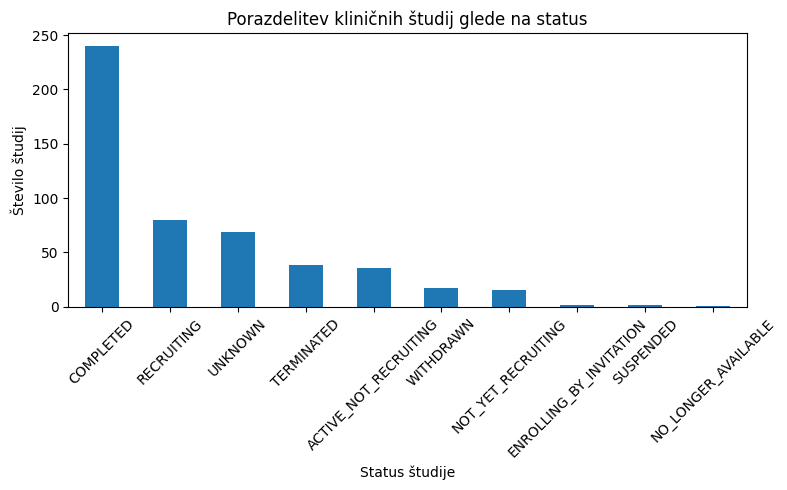

In [138]:
import matplotlib.pyplot as plt

status_counts = df["overall_status"].value_counts()

plt.figure(figsize=(8,5))
status_counts.plot(kind="bar")
plt.title("Porazdelitev kliničnih študij glede na status")
plt.xlabel("Status študije")
plt.ylabel("Število študij")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Graf prikazuje porazdelitev kliničnih študij, povezanih z rakom dojke, glede na njihov trenutni status. Največji delež predstavljajo zaključene študije (COMPLETED), kar nakazuje, da je velik del raziskav že dosegel končne rezultate. Pomemben delež študij je še v fazi vključevanja udeležencev (RECRUITING), kar pojasnjuje tudi prisotnost manjkajočih vrednosti pri končnem datumu in trajanju študije. Manjši delež predstavljajo študije z drugimi statusi, kot so TERMINATED, WITHDRAWN ali SUSPENDED, ki kažejo na raznolik potek kliničnih raziskav.

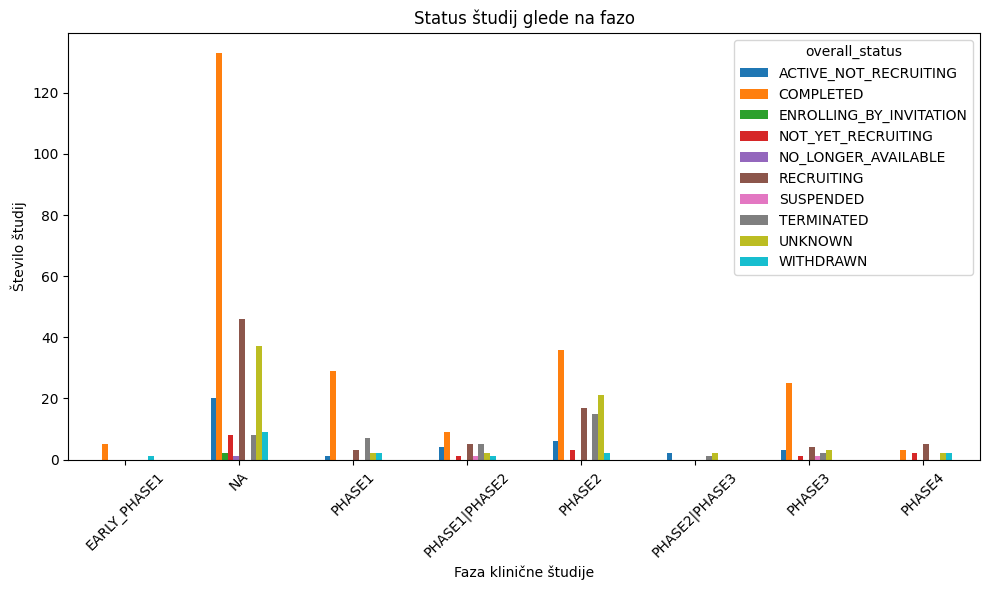

In [139]:
# napravi novu kolonu za plot: phases kao string
df["phases_plot"] = df["phases"].apply(lambda x: "|".join(x) if isinstance(x, list) else x)
df["phases_plot"] = df["phases_plot"].fillna("NA")

phase_status = (
    df.groupby(["phases_plot", "overall_status"])
      .size()
      .unstack(fill_value=0)
)

phase_status.plot(kind="bar", figsize=(10,6))
import matplotlib.pyplot as plt
plt.title("Status študij glede na fazo")
plt.xlabel("Faza klinične študije")
plt.ylabel("Število študij")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Graf prikazuje razmerje med fazo klinične študije in njenim trenutnim statusom. Opazimo, da največji delež študij brez jasno določene faze (NA) predstavlja zaključene ali še aktivne študije, kar je pogosto značilno za opazovalne ali neintervencijske raziskave.

Pri študijah v zgodnjih fazah (EARLY_PHASE1, PHASE1) prevladujejo študije, ki so še v teku ali so bile zaključene v manjšem obsegu, kar odraža raziskovalno naravo teh faz. V višjih fazah (PHASE2, PHASE3 in PHASE4) je opaziti večje število zaključenih študij, saj te faze običajno sledijo uspešnim predhodnim preizkusom in vključujejo večje število udeležencev.

Graf jasno kaže, da se z napredovanjem faze povečuje verjetnost zaključka študije, kar je skladno s pričakovanim potekom kliničnih raziskav.

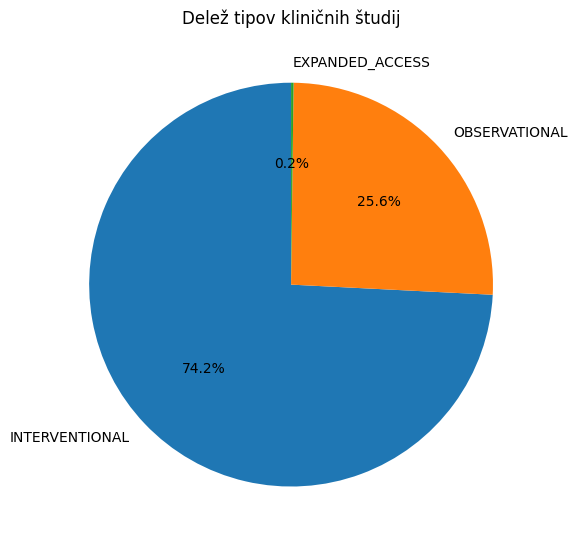

In [140]:
study_type_counts = df["study_type"].value_counts()

plt.figure(figsize=(6,6))
plt.pie(study_type_counts, labels=study_type_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Delež tipov kliničnih študij")
plt.tight_layout()
plt.show()


Krožni diagram prikazuje delež posameznih tipov kliničnih študij v obravnavani podatkovni množici. Opazimo, da večino predstavljajo intervencijske študije (INTERVENTIONAL), kar je pričakovano, saj so te usmerjene v preizkušanje učinkovitosti in varnosti novih terapevtskih pristopov. Pomemben delež predstavljajo tudi opazovalne študije (OBSERVATIONAL), ki se osredotočajo na spremljanje bolnikov brez neposrednega posega. Tip EXPANDED_ACCESS je zastopan le v zanemarljivem deležu, saj gre za specifične primere dostopa do eksperimentalnih terapij zunaj klasičnih kliničnih raziskav.

In [141]:
# srednja starost studije
df["mean_age"] = (df["min_age_years"] + df["max_age_years"]) / 2

# definicija starosnih grupa
bins = [0, 30, 40, 50, 60, 70, 120]
labels = ["<30", "30–39", "40–49", "50–59", "60–69", "70+"]

df["age_group"] = pd.cut(df["mean_age"], bins=bins, labels=labels, right=False)


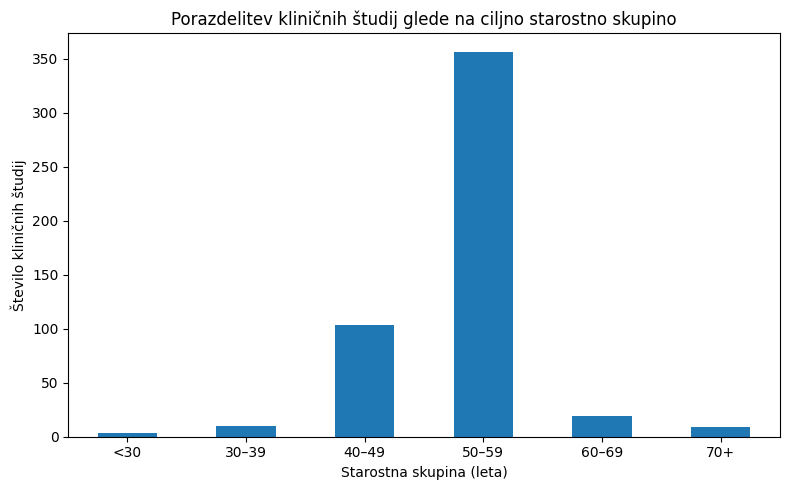

In [142]:
age_counts = df["age_group"].value_counts().sort_index()

plt.figure(figsize=(8,5))
age_counts.plot(kind="bar")
plt.title("Porazdelitev kliničnih študij glede na ciljno starostno skupino")
plt.xlabel("Starostna skupina (leta)")
plt.ylabel("Število kliničnih študij")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Graf prikazuje porazdelitev kliničnih študij glede na ciljne starostne skupine udeležencev, določene na podlagi povprečne starosti, izračunane iz minimalne in maksimalne dovoljene starosti v posamezni študiji. Opazimo izrazito prevlado študij, usmerjenih v starostno skupino 50–59 let, kar je skladno z epidemiološkimi podatki, ki kažejo, da se pojavnost raka dojke najpogosteje povečuje v srednjem in višjem starostnem obdobju.

Manjši delež študij vključuje mlajše starostne skupine, kar odraža nižjo pojavnost bolezni pri mlajših osebah, medtem ko so tudi študije, usmerjene v najstarejše starostne skupine, manj zastopane, kar je lahko povezano z večjimi zdravstvenimi omejitvami in etičnimi izzivi pri vključevanju starejših udeležencev v klinične raziskave.

## Gručenje kliničnih študij

### Namen in motivacija

Poleg nadzorovanih metod strojnega učenja je bila v okviru projekta uporabljena tudi metoda **gručenja**, ki spada med nenadzorovane pristope analize podatkov. Namen gručenja ni napovedovanje vnaprej določene ciljne spremenljivke, temveč odkrivanje skritih vzorcev in podobnosti med primerki v podatkovni množici.

V kontekstu kliničnih študij, povezanih z rakom dojke, je gručenje smiselno za identifikacijo **različnih tipov oziroma profilov študij** glede na njihovo kompleksnost, obseg in ciljno populacijo. Takšna analiza omogoča boljše razumevanje, kako se klinične raziskave razlikujejo med seboj, ter razkriva značilnosti manjših, srednje velikih in obsežnih raziskav.

Za namen gručenja so bile uporabljene izbrane numerične značilnice, ki opisujejo strukturo in obseg posamezne klinične študije, kot so število obravnavanih stanj, število intervencij, število vključenih držav, starostni razpon udeležencev ter trajanje študije. Na ta način je bilo mogoče primerke razvrstiti v smiselne skupine brez vnaprej določenih oznak.


In [143]:
features_cluster = [
    "n_conditions",
    "n_interventions",
    "n_countries",
    "min_age_years",
    "max_age_years",
    "duration_days"
]


In [144]:
df_cluster = df[features_cluster].dropna()

In [145]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_cluster)

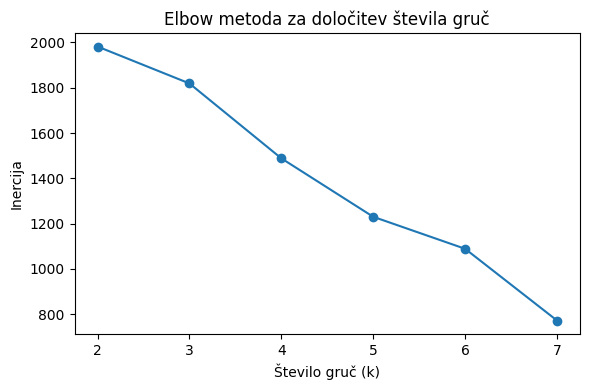

In [146]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
K = range(2, 8)

for k in K:
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(6,4))
plt.plot(K, inertia, marker="o")
plt.xlabel("Število gruč (k)")
plt.ylabel("Inercija")
plt.title("Elbow metoda za določitev števila gruč")
plt.tight_layout()
plt.show()

In [147]:
kmeans = KMeans(n_clusters=4, random_state=42)
df_cluster["cluster"] = kmeans.fit_predict(X_scaled)

In [148]:
cluster_summary = df_cluster.groupby("cluster").mean()
cluster_summary

,n_conditions,n_interventions,n_countries,min_age_years,max_age_years,duration_days
cluster,,,,,,
0,2.103261,1.364130,0.0,18.320652,85.494565,1503.801630
1,1.571429,1.628571,0.0,43.600000,79.085714,1757.085714
2,1.000000,0.000000,0.0,18.000000,90.000000,22249.000000
3,5.466667,5.106667,0.0,18.240000,87.773333,2115.280000


Gruče so bile oblikovane na podlagi skupne podobnosti kliničnih študij glede na več numeričnih značilnic hkrati. Največji vpliv na razvrščanje so imeli trajanje študije, število intervencij in število obravnavanih stanj, ki skupaj odražajo kompleksnost in obseg raziskave. Dodatno vlogo ima tudi ciljna starostna skupina udeležencev, kar omogoča razlikovanje študij, usmerjenih v starejšo populacijo.


#Klasifikacija
Za nadzorovano učenje je bila izbrana klasifikacija, pri kateri je ciljna spremenljivka *overall_status*. Namen klasifikacije je napovedati trenutni status klinične študije na podlagi njenih strukturnih, demografskih in časovnih značilnosti. Takšna napoved omogoča boljše razumevanje dejavnikov, ki vplivajo na uspešen potek in zaključek kliničnih raziskav, povezanih z rakom dojke.


In [149]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [150]:
df_bin = df.copy()

df_bin["target_completed"] = df_bin["overall_status"].apply(
    lambda x: 1 if x == "COMPLETED" else 0
)

df_bin["target_completed"].value_counts()


,count
target_completed,
0,260
1,240


In [151]:
features = [
    "n_conditions",
    "n_interventions",
    "n_countries",
    "min_age_years",
    "max_age_years",
    "duration_days"
]

X = df_bin[features]
y = df_bin["target_completed"]


In [152]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


In [153]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

In [154]:
pipeline.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=200, random_state=42))])

In [155]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred = pipeline.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification report:\n")
print(classification_report(y_test, y_pred))

Accuracy: 0.6

Classification report:

              precision    recall  f1-score   support

           0       0.61      0.63      0.62        65
           1       0.59      0.57      0.58        60

    accuracy                           0.60       125
   macro avg       0.60      0.60      0.60       125
weighted avg       0.60      0.60      0.60       125



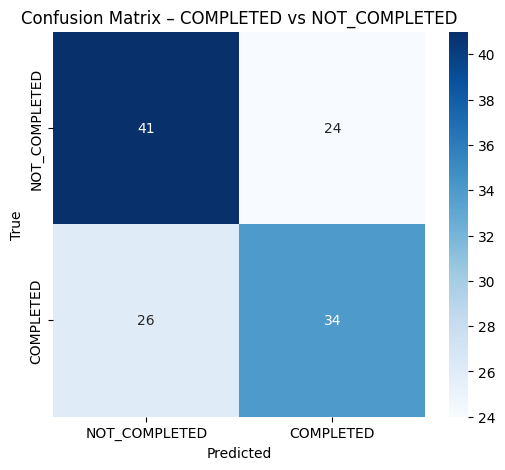

In [156]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NOT_COMPLETED", "COMPLETED"],
    yticklabels=["NOT_COMPLETED", "COMPLETED"]
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix – COMPLETED vs NOT_COMPLETED")
plt.show()

Za binarno klasifikacijo smo status kliničnih študij poenostavili na dve kategoriji: COMPLETED in NOT_COMPLETED. Takšna formulacija problema se je izkazala za ustreznejšo v primerjavi z večrazredno klasifikacijo, saj omogoča stabilnejše in bolj uravnotežene rezultate.

Model doseže natančnost približno 60 %, pri čemer sta precision in recall razmeroma uravnotežena za obe razreda. Analiza konfuzijske matrike pokaže, da model uspešno prepozna večino zaključenih študij, hkrati pa ne kaže izrazite pristranskosti do posamezne kategorije.

Kljub temu rezultati potrjujejo, da je napovedovanje uspešnega zaključka klinične študije omejeno zaradi pomanjkanja ključnih zunanjih dejavnikov (npr. financiranje, uspešnost terapije, organizacijski razlogi), ki niso vključeni v podatkovni nabor. V tem kontekstu predstavljeni model ponuja realističen in interpretabilen vpogled v omejitve napovedovanja na podlagi razpoložljivih podatkov.


Napovedovanje verjetnosti, da se klinična študija uspešno zaključi, ima pomembno praktično vrednost. Takšni modeli lahko služijo kot podporno orodje pri odločanju o razporejanju finančnih, organizacijskih in človeških virov. Na podlagi strukturnih značilnosti študije (npr. faza, trajanje, starostna skupina udeležencev, kompleksnost intervencij) je mogoče identificirati študije, ki imajo večjo verjetnost uspešnega zaključka.

To omogoča usmerjanje večjih vlaganj v projekte z višjim potencialom za dokončanje, hkrati pa zgodnje prepoznavanje študij, ki bi lahko naletele na težave in bi zato zahtevale dodatno podporo ali prilagoditve zasnove. V širšem kontekstu tak pristop prispeva k učinkovitejši porabi raziskovalnih sredstev ter pospeševanju razvoja novih terapij in diagnostičnih pristopov na področju raka dojke.

# Regresija: napoved trajanja kliničnih študij

V tem delu projekta uporabimo regresijski pristop za napoved trajanja kliničnih študij, izraženega v številu dni (`duration_days`). Za razliko od klasifikacije statusa študije, kjer so rezultati omejeni zaradi vpliva zunanjih dejavnikov, je trajanje študije bolj neposredno povezano s strukturnimi lastnostmi raziskave, kot so ko_


In [157]:
df_reg = df.copy()

features = [
    "n_conditions",
    "n_interventions",
    "n_countries",
    "min_age_years",
    "max_age_years"
]
target = "duration_days"

df_reg = df_reg[df_reg[target].notna()].copy()

X = df_reg[features]
y = df_reg[target]

print("Broj instanci za regresiju:", len(df_reg))
print("Missing u y:", y.isna().sum())


Broj instanci za regresiju: 479
Missing u y: 0


In [158]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42
)

In [159]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor

pipeline_reg = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])

In [160]:
pipeline_reg.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model',
                 RandomForestRegressor(n_estimators=200, random_state=42))])

In [161]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = pipeline_reg.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R²:", round(r2, 3))

MAE: 1215.43
RMSE: 2424.7
R²: -0.061


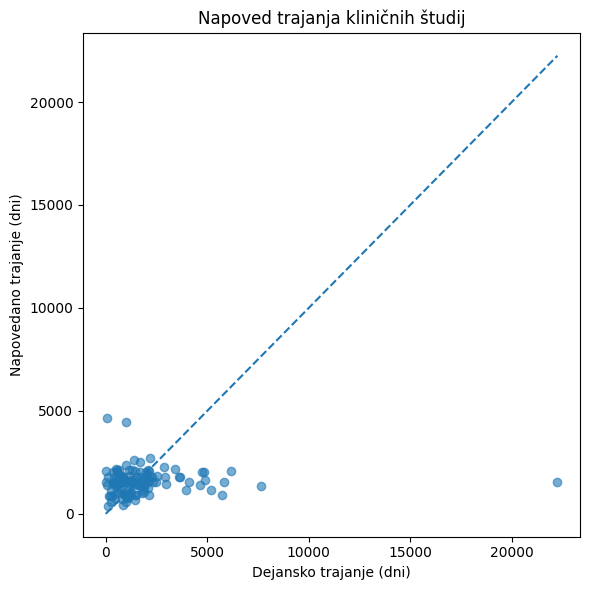

In [162]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         linestyle="--")

plt.xlabel("Dejansko trajanje (dni)")
plt.ylabel("Napovedano trajanje (dni)")
plt.title("Napoved trajanja kliničnih študij")
plt.tight_layout()
plt.show()

In [163]:
import pandas as pd

importances = pipeline_reg.named_steps["model"].feature_importances_

fi = pd.Series(importances, index=features).sort_values(ascending=False)
fi

,0
max_age_years,0.303660
min_age_years,0.276295
n_interventions,0.239359
n_conditions,0.180687
n_countries,0.000000


V okviru projekta smo poskusili z regresijskimi modeli napovedati dejansko trajanje kliničnih študij (v dnevih) na podlagi osnovnih značilnosti študije, kot so število obravnavanih stanj, število intervencij, število vključenih držav ter ciljni starostni razpon udeležencev.

Rezultati regresijskega modela so pokazali nizko napovedno moč, kar se odraža v negativni oziroma zelo nizki vrednosti koeficienta
𝑅2 ter relativno visokih napakah (MAE in RMSE). To pomeni, da model ni sposoben zanesljivo pojasniti variabilnosti dejanskega trajanja kliničnih študij.

Razlog za to je predvsem v naravi podatkov: trajanje kliničnih študij je močno odvisno od številnih zunanjih in neopaženih dejavnikov (regulativni postopki, logistične zamude, težave pri vključevanju udeležencev, finančne omejitve ipd.), ki v podatkovni množici niso zajeti.

## Klasifikacija trajanja kliničnih študij (SHORT / MEDIUM / LONG)

Ker regresijski modeli niso uspeli zanesljivo napovedati natančnega trajanja kliničnih študij, smo problem reformulirali v klasifikacijski pristop. Namesto napovedi točnega števila dni trajanja študije razvrstimo študije v širše časovne razrede, kar omogoča stabilnejše in bolj interpretabilne rezultate.

Trajanje študij smo razdelili v tri kategorije:
- SHORT: trajanje krajše od 2 let,
- MEDIUM: trajanje med 2 in 5 let,
- LONG: trajanje daljše od 5 let.

Takšna razdelitev je smiselna z vidika načrtovanja kliničnih raziskav, saj omogoča grobo oceno časovne zahtevnosti študije.


In [164]:
df_dur = df.copy()

df_dur = df_dur[df_dur["duration_days"].notna()].copy()

def duration_class(days):
    if days < 365 * 2:
        return "SHORT"
    elif days <= 365 * 5:
        return "MEDIUM"
    else:
        return "LONG"

df_dur["duration_class"] = df_dur["duration_days"].apply(duration_class)

df_dur["duration_class"].value_counts()


,count
duration_class,
MEDIUM,212
LONG,153
SHORT,114


In [165]:
features = [
    "n_conditions",
    "n_interventions",
    "n_countries",
    "min_age_years",
    "max_age_years"
]

X = df_dur[features]
y = df_dur["duration_class"]


In [166]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

In [167]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

pipeline_dur = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])


In [168]:
from sklearn.metrics import classification_report, accuracy_score

pipeline_dur.fit(X_train, y_train)

y_pred = pipeline_dur.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification report:\n")
print(classification_report(y_test, y_pred))


Accuracy: 0.38333333333333336

Classification report:

              precision    recall  f1-score   support

        LONG       0.32      0.32      0.32        38
      MEDIUM       0.47      0.40      0.43        53
       SHORT       0.34      0.45      0.39        29

    accuracy                           0.38       120
   macro avg       0.38      0.39      0.38       120
weighted avg       0.39      0.38      0.38       120



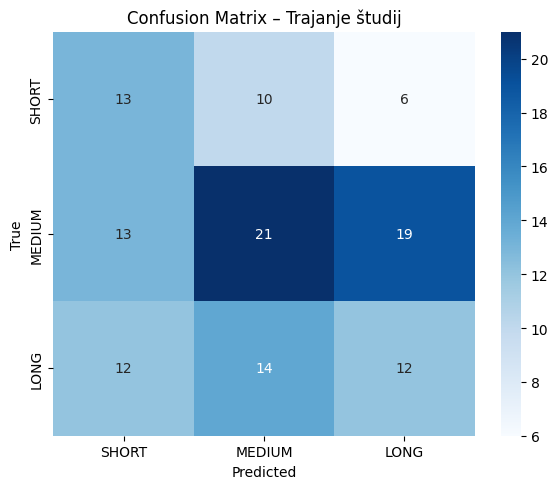

In [169]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=["SHORT", "MEDIUM", "LONG"])

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["SHORT", "MEDIUM", "LONG"],
    yticklabels=["SHORT", "MEDIUM", "LONG"]
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix – Trajanje študij")
plt.tight_layout()
plt.show()


Na podlagi izvedenih eksperimentov lahko ugotovimo, da je z uporabo razpoložljivih strukturnih podatkov mogoče zmerno uspešno napovedati, ali se bo klinična študija zaključila (COMPLETED) ali ne. Binarna klasifikacija statusa študije se je izkazala za stabilnejšo in bolj zanesljivo v primerjavi z večrazrednimi in regresijskimi pristopi.

Nasprotno pa napovedovanje trajanja kliničnih študij, bodisi z regresijo bodisi s klasifikacijo v časovne razrede (SHORT, MEDIUM, LONG), ni dalo zadovoljivih rezultatov. Nizke vrednosti natančnosti in F1-mera ter izrazito prekrivanje razredov kažejo, da trajanje študije v veliki meri določajo zunanji dejavniki, ki v podatkovnem naboru niso zajeti (npr. regulatorni postopki, financiranje, organizacijski in medicinski razlogi).

Rezultati potrjujejo, da je status zaključka študije bolj neposredno povezan s splošnimi značilnostmi raziskave, medtem ko je trajanje bistveno bolj kompleksna in težje napovedljiva lastnost. Takšna ugotovitev poudarja pomen kakovostnih in vsebinsko bogatejših podatkov pri uporabi metod strojnega učenja v domeni kliničnih raziskav.
